In [1]:
pip install pandas numpy scikit-learn matplotlib seaborn jupyter


   ------------- -------------------------- 2/6 [lark]
   ------------- -------------------------- 2/6 [lark]
   --------------------------------- ------ 5/6 [isoduration]
   ---------------------------------------- 6/6 [isoduration]

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate,
    train_test_split
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [3]:
df = pd.read_csv("data/train.csv")

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
df.shape

(891, 12)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [6]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [7]:
df["Survived"].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [8]:
baseline_features = [
    "Pclass", "Sex", "Age", "SibSp",
    "Parch", "Fare", "Embarked"
]

y = df["Survived"]

In [9]:
numeric_features = ["Age", "SibSp", "Parch", "Fare"]

categorical_features = ["Pclass", "Sex", "Embarked"]


def build_model(num_cols, cat_cols):

    num_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    cat_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer([
        ("num", num_pipeline, num_cols),
        ("cat", cat_pipeline, cat_cols)
    ])

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=2000))
    ])

    return model

In [10]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

baseline_model = build_model(
    numeric_features,
    categorical_features
)

baseline_scores = cross_validate(
    baseline_model,
    df[baseline_features],
    y,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "f1": "f1"
    }
)

baseline_accuracy = baseline_scores["test_accuracy"].mean()
baseline_f1 = baseline_scores["test_f1"].mean()

print("Baseline Accuracy:", baseline_accuracy)
print("Baseline F1 Score:", baseline_f1)

Baseline Accuracy: 0.7968740192078337
Baseline F1 Score: 0.7257926039978063


In [11]:
df_fe = df.copy()

In [12]:
df_fe["Title"] = df_fe["Name"].str.extract(
    r",\s*([^.]*)\.",
    expand=False
)

df_fe["Title"] = df_fe["Title"].fillna("Rare")

df_fe["Title"] = df_fe["Title"].replace({
    "Mlle": "Miss",
    "Ms": "Miss",
    "Mme": "Mrs"
})

df_fe["Title"] = df_fe["Title"].where(
    df_fe["Title"].isin(["Mr", "Mrs", "Miss", "Master"]),
    "Rare"
)

In [13]:
df_fe["FamilySize"] = (
    df_fe["SibSp"] +
    df_fe["Parch"] + 1
)

In [14]:
df_fe["IsAlone"] = (
    df_fe["FamilySize"] == 1
).astype(int)

In [15]:
df_fe["FarePerPerson"] = (
    df_fe["Fare"] / df_fe["FamilySize"]
)

In [16]:
df_fe["Deck"] = (
    df_fe["Cabin"]
    .fillna("Unknown")
    .astype(str)
    .str[0]
)

In [17]:
df_fe["HasCabin"] = (
    df_fe["Cabin"].notna()
).astype(int)

In [18]:
ticket_prefix = (
    df_fe["Ticket"]
    .astype(str)
    .str.replace(r"[\d\s./]", "", regex=True)
    .str.upper()
)

df_fe["TicketPrefix"] = ticket_prefix.replace(
    "", "NUMERIC"
)

In [19]:
df_fe["NameLength"] = df_fe["Name"].str.len()

In [20]:
df_fe["AgeGroup"] = pd.cut(
    df_fe["Age"],
    bins=[0, 12, 18, 35, 60, np.inf],
    labels=[
        "Child",
        "Teen",
        "YoungAdult",
        "Adult",
        "Senior"
    ],
    include_lowest=True
).astype("object")

In [21]:
df_fe["AgeMissing"] = (
    df_fe["Age"].isnull()
).astype(int)

In [22]:
new_features = [
    "Title",
    "FamilySize",
    "IsAlone",
    "FarePerPerson",
    "Deck",
    "HasCabin",
    "TicketPrefix",
    "NameLength",
    "AgeGroup",
    "AgeMissing"
]

df_fe[new_features].head()

,Title,FamilySize,IsAlone,FarePerPerson,Deck,HasCabin,TicketPrefix,NameLength,AgeGroup,AgeMissing
0,Mr,2,0,3.62500,U,0,A,23,YoungAdult,0
1,Mrs,2,0,35.64165,C,1,PC,51,Adult,0
2,Miss,1,1,7.92500,U,0,STONO,22,YoungAdult,0
3,Mrs,2,0,26.55000,C,1,NUMERIC,44,YoungAdult,0
4,Mr,1,1,8.05000,U,0,NUMERIC,24,YoungAdult,0


In [23]:
all_numeric_features = [
    "Age", "SibSp", "Parch", "Fare",
    "FamilySize", "IsAlone", "FarePerPerson",
    "HasCabin", "NameLength", "AgeMissing"
]

all_categorical_features = [
    "Pclass", "Sex", "Embarked",
    "Title", "Deck", "TicketPrefix", "AgeGroup"
]

In [24]:
def evaluate(features):

    num_cols = [
        col for col in features
        if col in all_numeric_features
    ]

    cat_cols = [
        col for col in features
        if col in all_categorical_features
    ]

    model = build_model(num_cols, cat_cols)

    scores = cross_validate(
        model,
        df_fe[features],
        y,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "f1": "f1"
        }
    )

    return {
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV F1": scores["test_f1"].mean()
    }

In [25]:
results = []

baseline_result = evaluate(baseline_features)

results.append({
    "Experiment": "Baseline",
    **baseline_result
})

for feature in new_features:

    features = baseline_features + [feature]

    score = evaluate(features)

    results.append({
        "Experiment": "Baseline + " + feature,
        **score
    })

full_features = baseline_features + new_features

full_result = evaluate(full_features)

results.append({
    "Experiment": "All 10 Features",
    **full_result
})

results_df = pd.DataFrame(results)

results_df.sort_values(
    by="CV Accuracy",
    ascending=False
)

,Experiment,CV Accuracy,CV F1
1,Baseline + Title,0.828284,0.770258
11,All 10 Features,0.822635,0.763717
9,Baseline + AgeGroup,0.811456,0.743568
5,Baseline + Deck,0.804702,0.737479
6,Baseline + HasCabin,0.802467,0.733435
8,Baseline + NameLength,0.801356,0.731775
7,Baseline + TicketPrefix,0.800226,0.727588
3,Baseline + IsAlone,0.799127,0.727145
2,Baseline + FamilySize,0.797991,0.726845
0,Baseline,0.796874,0.725793


In [26]:
ablation_results = []

for feature in new_features:

    reduced_features = [
        col for col in full_features
        if col != feature
    ]

    score_without = evaluate(reduced_features)

    accuracy_drop = (
        full_result["CV Accuracy"]
        - score_without["CV Accuracy"]
    )

    ablation_results.append({
        "Feature Removed": feature,
        "Accuracy Without Feature": score_without["CV Accuracy"],
        "Accuracy Drop": accuracy_drop
    })

ablation_df = pd.DataFrame(ablation_results)

ablation_df.sort_values(
    by="Accuracy Drop",
    ascending=False
)

,Feature Removed,Accuracy Without Feature,Accuracy Drop
0,Title,0.805813,0.016823
1,FamilySize,0.821518,0.001117
2,IsAlone,0.821518,0.001117
5,HasCabin,0.822635,0.000000
8,AgeGroup,0.822641,-0.000006
7,NameLength,0.822641,-0.000006
9,AgeMissing,0.824882,-0.002247
3,FarePerPerson,0.824889,-0.002253
4,Deck,0.824907,-0.002272
6,TicketPrefix,0.828266,-0.005631


In [27]:
train_idx, test_idx = train_test_split(
    df_fe.index,
    test_size=0.2,
    random_state=42,
    stratify=y
)

y_train = y.loc[train_idx]
y_test = y.loc[test_idx]

In [28]:
baseline_model = build_model(
    numeric_features,
    categorical_features
)

baseline_model.fit(
    df_fe.loc[train_idx, baseline_features],
    y_train
)

baseline_predictions = baseline_model.predict(
    df_fe.loc[test_idx, baseline_features]
)

In [29]:
full_model = build_model(
    all_numeric_features,
    all_categorical_features
)

full_model.fit(
    df_fe.loc[train_idx, full_features],
    y_train
)

full_predictions = full_model.predict(
    df_fe.loc[test_idx, full_features]
)

In [30]:
print("Baseline Test Accuracy:",
      accuracy_score(y_test, baseline_predictions))

print("Feature Engineered Test Accuracy:",
      accuracy_score(y_test, full_predictions))

print("Baseline F1:",
      f1_score(y_test, baseline_predictions))

print("Feature Engineered F1:",
      f1_score(y_test, full_predictions))

Baseline Test Accuracy: 0.8044692737430168
Feature Engineered Test Accuracy: 0.8156424581005587
Baseline F1: 0.7244094488188977
Feature Engineered F1: 0.7591240875912408


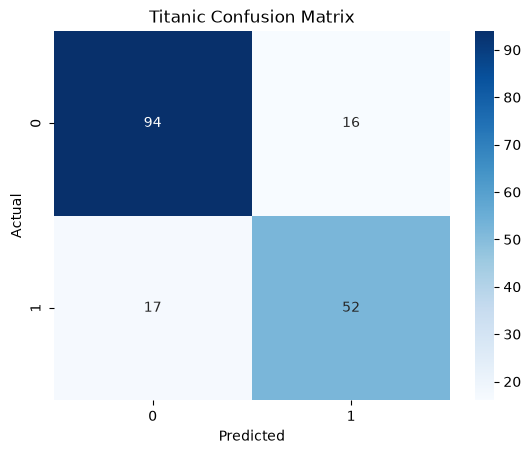

In [31]:
cm = confusion_matrix(y_test, full_predictions)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Titanic Confusion Matrix")

plt.show()

In [32]:
print(
    classification_report(
        y_test,
        full_predictions
    )
)

              precision    recall  f1-score   support

           0       0.85      0.85      0.85       110
           1       0.76      0.75      0.76        69

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.82      0.82      0.82       179



In [33]:
error_df = df_fe.loc[
    test_idx,
    ["PassengerId", "Name", "Sex", "Age", "Pclass"]
].copy()

error_df["Actual"] = y_test
error_df["Predicted"] = full_predictions

wrong_predictions = error_df[
    error_df["Actual"] != error_df["Predicted"]
]

wrong_predictions.head(10)

,PassengerId,Name,Sex,Age,Pclass,Actual,Predicted
553,554,"Leeni, Mr. Fahim (""Philip Zenni"")",male,22.0,3,1,0
536,537,"Butt, Major. Archibald Willingham",male,45.0,1,0,1
712,713,"Taylor, Mr. Elmer Zebley",male,48.0,1,1,0
455,456,"Jalsevac, Mr. Ivan",male,29.0,3,1,0
65,66,"Moubarek, Master. Gerios",male,NaN,3,1,0
297,298,"Allison, Miss. Helen Loraine",female,2.0,1,0,1
40,41,"Ahlin, Mrs. Johan (Johanna Persdotter Larsson)",female,40.0,3,0,1
564,565,"Meanwell, Miss. (Marion Ogden)",female,NaN,3,0,1
502,503,"O'Sullivan, Miss. Bridget Mary",female,NaN,3,0,1
17,18,"Williams, Mr. Charles Eugene",male,NaN,2,1,0


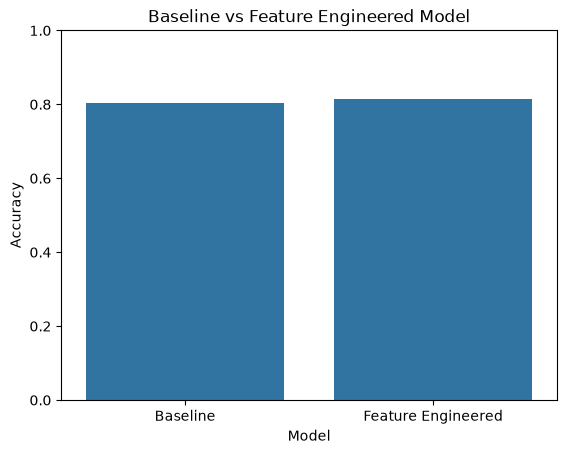

In [34]:
comparison = pd.DataFrame({
    "Model": ["Baseline", "Feature Engineered"],
    "Accuracy": [
        accuracy_score(y_test, baseline_predictions),
        accuracy_score(y_test, full_predictions)
    ]
})

sns.barplot(
    data=comparison,
    x="Model",
    y="Accuracy"
)

plt.title("Baseline vs Feature Engineered Model")
plt.ylim(0, 1)

plt.show()